In [1]:
# =====================================================
# PHASE 5: MACHINE LEARNING MODEL DEVELOPMENT
# STEP 1: IMPORT LIBRARIES AND LOAD DATA
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import os
import warnings

warnings.filterwarnings("ignore")

# Machine Learning libraries
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

print("Libraries imported successfully!")

# Load processed datasets
X_train = pd.read_csv(
    "../data/processed/X_train_final.csv"
)

X_test = pd.read_csv(
    "../data/processed/X_test_final.csv"
)

y_train = pd.read_csv(
    "../data/processed/y_train.csv"
).squeeze("columns")

y_test = pd.read_csv(
    "../data/processed/y_test.csv"
).squeeze("columns")

print("\nDatasets loaded successfully!")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Libraries imported successfully!

Datasets loaded successfully!
X_train: (8000, 10)
X_test: (2000, 10)
y_train: (8000,)
y_test: (2000,)


In [2]:
# =====================================================
# STEP 2: DATA VALIDATION
# =====================================================

print("Training Missing Values:",
      X_train.isnull().sum().sum())

print("Testing Missing Values:",
      X_test.isnull().sum().sum())

print("Training Infinite Values:",
      np.isinf(X_train.select_dtypes(include=np.number)).sum().sum())

print("Testing Infinite Values:",
      np.isinf(X_test.select_dtypes(include=np.number)).sum().sum())

print("\nTraining Target Classes:")
print(y_train.value_counts())

print("\nTesting Target Classes:")
print(y_test.value_counts())

Training Missing Values: 0
Testing Missing Values: 0
Training Infinite Values: 0
Testing Infinite Values: 0

Training Target Classes:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing Target Classes:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [3]:
assert set(y_train.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

assert X_train.shape[0] == y_train.shape[0]
assert X_test.shape[0] == y_test.shape[0]

print("Data validation successful!")

Data validation successful!


In [4]:
# =====================================================
# STEP 3.1: TARGET CLASS DISTRIBUTION
# =====================================================

print("Training Target Distribution:")

print(y_train.value_counts())

print("\nPercentage Distribution:")

print(y_train.value_counts(normalize=True) * 100)

Training Target Distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Percentage Distribution:
Machine failure
0    96.6125
1     3.3875
Name: proportion, dtype: float64


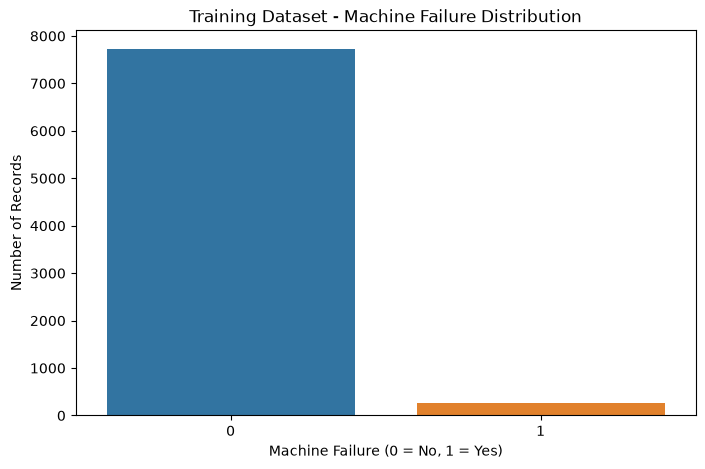

In [5]:
# =====================================================
# STEP 3.2: CLASS IMBALANCE VISUALIZATION
# =====================================================

plt.figure(figsize=(8, 5))

sns.countplot(
    x=y_train,
    hue=y_train,
    legend=False
)

plt.title("Training Dataset - Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.show()

In [6]:
# =====================================================
# STEP 3.3: CLASS IMBALANCE RATIO
# =====================================================

class_counts = y_train.value_counts()

majority_count = class_counts.max()
minority_count = class_counts.min()

imbalance_ratio = majority_count / minority_count

print("Majority Class:", majority_count)
print("Minority Class:", minority_count)

print("Imbalance Ratio:", round(imbalance_ratio, 2))

Majority Class: 7729
Minority Class: 271
Imbalance Ratio: 28.52


In [7]:
# =====================================================
# STEP 4: BASELINE MODEL
# =====================================================

from sklearn.dummy import DummyClassifier

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

baseline_model.fit(
    X_train,
    y_train
)

baseline_predictions = baseline_model.predict(X_test)

print("Baseline Model Accuracy:",
      baseline_model.score(X_test, y_test))

Baseline Model Accuracy: 0.966


In [8]:
# =====================================================
# STEP 5: MODEL EVALUATION FUNCTION
# =====================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

def evaluate_model(model, X_data, y_true, threshold=0.5):

    probabilities = model.predict_proba(X_data)[:, 1]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    results = {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),
        "PR-AUC": average_precision_score(
            y_true, probabilities
        )
    }

    return results

In [9]:
# =====================================================
# STEP 6: LOGISTIC REGRESSION
# =====================================================

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

logistic_model.fit(
    X_train,
    y_train
)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [10]:
logistic_results = evaluate_model(
    logistic_model,
    X_test,
    y_test
)

print("Logistic Regression Results:")

pd.DataFrame(
    [logistic_results],
    index=["Logistic Regression"]
)

Logistic Regression Results:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.8585,0.177177,0.867647,0.294264,0.933953,0.46588


In [11]:
# =====================================================
# STEP 7: DECISION TREE
# =====================================================

from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=6,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

decision_tree_model.fit(
    X_train,
    y_train
)

print("Decision Tree Training Completed!")

Decision Tree Training Completed!


In [12]:
decision_tree_results = evaluate_model(
    decision_tree_model,
    X_test,
    y_test
)

pd.DataFrame(
    [decision_tree_results],
    index=["Decision Tree"]
)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Decision Tree,0.9595,0.450382,0.867647,0.592965,0.899597,0.806416


In [13]:
# =====================================================
# STEP 8: RANDOM FOREST
# =====================================================

from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [14]:
random_forest_results = evaluate_model(
    random_forest_model,
    X_test,
    y_test
)

pd.DataFrame(
    [random_forest_results],
    index=["Random Forest"]
)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Random Forest,0.976,0.602041,0.867647,0.710843,0.977131,0.857108


In [19]:
import re

# Create a copy to preserve original column names
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

# Clean column names
def clean_column_names(columns):
    cleaned = []

    for col in columns:
        col = re.sub(r"[\[\]<>]", "", col)
        col = col.replace(" ", "_")
        cleaned.append(col)

    return cleaned

X_train_xgb.columns = clean_column_names(X_train_xgb.columns)
X_test_xgb.columns = clean_column_names(X_test_xgb.columns)

print("Cleaned feature names:")
print(X_train_xgb.columns.tolist())

Cleaned feature names:
['numerical__Air_temperature_K', 'numerical__Process_temperature_K', 'numerical__Rotational_speed_rpm', 'numerical__Torque_Nm', 'numerical__Tool_wear_min', 'numerical__Temperature_Difference_K', 'numerical__Mechanical_Power_kW', 'categorical__Type_H', 'categorical__Type_L', 'categorical__Type_M']


In [21]:
from xgboost import XGBClassifier

# Calculate class imbalance weight
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_weight = negative_count / positive_count

# Create model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train_xgb, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [23]:
xgb_results = evaluate_model(
    xgb_model,
    X_test_xgb,
    y_test
)

pd.DataFrame(
    [xgb_results],
    index=["XGBoost"]
)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
XGBoost,0.983,0.707317,0.852941,0.773333,0.981465,0.885029


In [25]:
model_comparison = pd.DataFrame(
    [
        logistic_results,
        decision_tree_results,
        random_forest_results,
        xgb_results
    ],
    index=[
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ]
)

model_comparison.sort_values(
    by="PR-AUC",
    ascending=False
)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
XGBoost,0.9830,0.707317,0.852941,0.773333,0.981465,0.885029
Random Forest,0.9760,0.602041,0.867647,0.710843,0.977131,0.857108
Decision Tree,0.9595,0.450382,0.867647,0.592965,0.899597,0.806416
Logistic Regression,0.8585,0.177177,0.867647,0.294264,0.933953,0.465880


In [26]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_xgb,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model Training Data:", X_fit.shape)
print("Validation Data:", X_val.shape)

print("\nTraining class distribution:")
print(y_fit.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

Model Training Data: (6400, 10)
Validation Data: (1600, 10)

Training class distribution:
Machine failure
0    6183
1     217
Name: count, dtype: int64

Validation class distribution:
Machine failure
0    1546
1      54
Name: count, dtype: int64


In [27]:
from xgboost import XGBClassifier

negative_count = (y_fit == 0).sum()
positive_count = (y_fit == 1).sum()

scale_weight = negative_count / positive_count

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_fit, y_fit)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [28]:
xgb_validation_results = evaluate_model(
    xgb_model,
    X_val,
    y_val
)

pd.DataFrame(
    [xgb_validation_results],
    index=["XGBoost Validation"]
)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
XGBoost Validation,0.985,0.767857,0.796296,0.781818,0.981505,0.825302


In [29]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from xgboost import XGBClassifier
import numpy as np

# Calculate class weight from model-training data
negative_count = (y_fit == 0).sum()
positive_count = (y_fit == 1).sum()

scale_weight = negative_count / positive_count

# Base model
xgb_base = XGBClassifier(
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)

# Hyperparameter search space
param_grid = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "gamma": [0, 0.1, 0.2, 0.3]
}

# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Randomized search
random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=25,
    scoring="average_precision",
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# Fit using training split only
random_search.fit(X_fit, y_fit)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(random_search.best_score_)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best Parameters:
{'subsample': 0.9, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'gamma': 0.1, 'colsample_bytree': 0.8}

Best Cross-Validation PR-AUC:
0.8590669916187192


In [30]:
best_xgb_model = random_search.best_estimator_

y_val_pred_tuned = best_xgb_model.predict(X_val)

y_val_prob_tuned = best_xgb_model.predict_proba(X_val)[:, 1]

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("TUNED XGBOOST - VALIDATION RESULTS")
print("----------------------------------")

print("Accuracy:", accuracy_score(y_val, y_val_pred_tuned))
print("Precision:", precision_score(y_val, y_val_pred_tuned))
print("Recall:", recall_score(y_val, y_val_pred_tuned))
print("F1 Score:", f1_score(y_val, y_val_pred_tuned))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_tuned))
print("PR-AUC:", average_precision_score(y_val, y_val_prob_tuned))

TUNED XGBOOST - VALIDATION RESULTS
----------------------------------
Accuracy: 0.98375
Precision: 0.7592592592592593
Recall: 0.7592592592592593
F1 Score: 0.7592592592592593
ROC-AUC: 0.9799003401849458
PR-AUC: 0.8280997219243799


In [31]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

threshold_results = []

thresholds = np.arange(0.10, 0.91, 0.05)

for threshold in thresholds:

    y_pred_threshold = (
        y_val_prob_tuned >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, y_pred_threshold),
        "Precision": precision_score(
            y_val, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred_threshold, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_pred_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.10,0.9631,0.4742,0.8519,0.6093
1,0.15,0.9719,0.5556,0.8333,0.6667
2,0.20,0.9762,0.6111,0.8148,0.6984
3,0.25,0.9788,0.6515,0.7963,0.7167
4,0.30,0.9819,0.7119,0.7778,0.7434
5,0.35,0.9831,0.7368,0.7778,0.7568
6,0.40,0.9838,0.7500,0.7778,0.7636
7,0.45,0.9838,0.7500,0.7778,0.7636
8,0.50,0.9838,0.7593,0.7593,0.7593
9,0.55,0.9838,0.7692,0.7407,0.7547


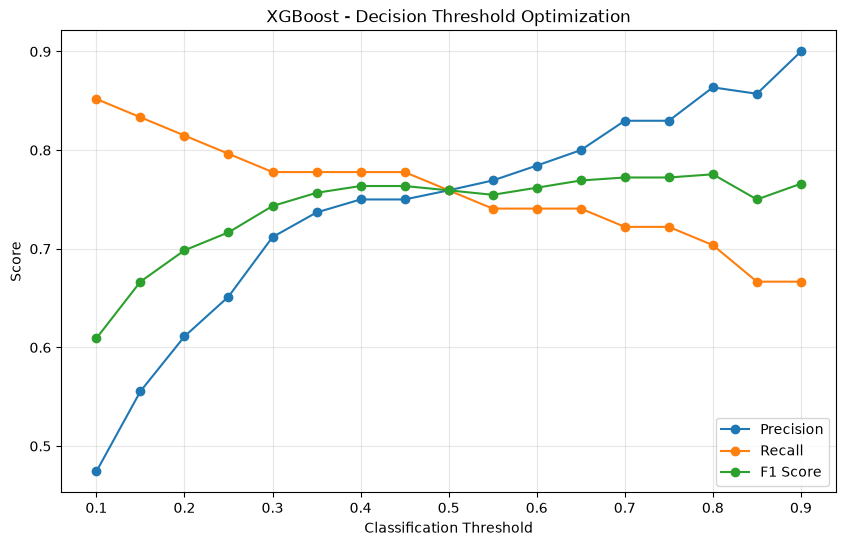

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("XGBoost - Decision Threshold Optimization")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

XGBOOST - VALIDATION PERFORMANCE
---------------------------------
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1546
     Failure       0.75      0.78      0.76        54

    accuracy                           0.98      1600
   macro avg       0.87      0.88      0.88      1600
weighted avg       0.98      0.98      0.98      1600



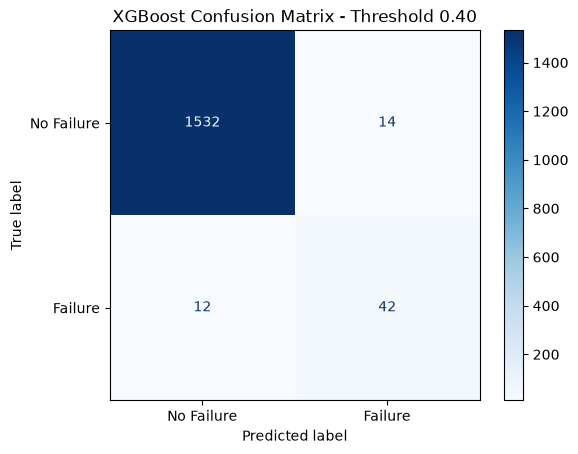

In [33]:
# Selected decision threshold
best_threshold = 0.40

# Predict using validation probabilities
y_val_pred_final = (
    y_val_prob_tuned >= best_threshold
).astype(int)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("XGBOOST - VALIDATION PERFORMANCE")
print("---------------------------------")

print(classification_report(
    y_val,
    y_val_pred_final,
    target_names=["No Failure", "Failure"]
))

# Confusion matrix
cm = confusion_matrix(y_val, y_val_pred_final)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("XGBoost Confusion Matrix - Threshold 0.40")
plt.show()

In [34]:
%pip install shap

   ---------------------------------------- 0.0/554.9 kB ? eta -:--:--
   ------------------ --------------------- 262.1/554.9 kB ? eta -:--:--
   ---------------------------------------- 554.9/554.9 kB 1.4 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


In [35]:
import shap
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.51.0


In [36]:
# Create SHAP explainer
explainer = shap.TreeExplainer(best_xgb_model)

# Calculate SHAP values on validation data
shap_values = explainer.shap_values(X_val)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


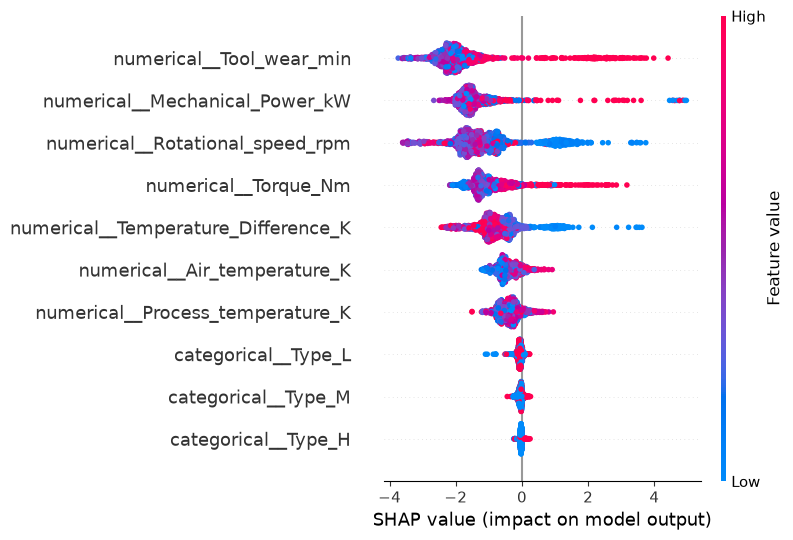

In [37]:
shap.summary_plot(
    shap_values,
    X_val,
    plot_type="dot",
    show=True
)

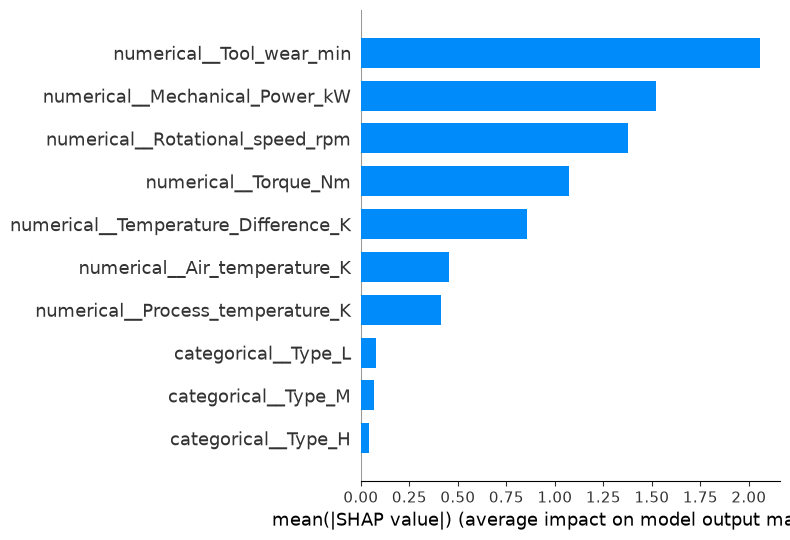

In [38]:
shap.summary_plot(
    shap_values,
    X_val,
    plot_type="bar",
    show=True
)

In [39]:
# Select one validation machine
sample_index = 0

sample = X_val.iloc[[sample_index]]

# Predict failure probability
failure_probability = best_xgb_model.predict_proba(sample)[0][1]

# Apply selected threshold
prediction = int(failure_probability >= 0.40)

print("MACHINE FAILURE EXPLANATION")
print("---------------------------")

print("Failure Probability:", round(failure_probability * 100, 2), "%")

print("Predicted Status:",
      "Failure Risk" if prediction == 1 else "Normal")

print("Selected Threshold: 0.40")

MACHINE FAILURE EXPLANATION
---------------------------
Failure Probability: 0.03 %
Predicted Status: Normal
Selected Threshold: 0.40


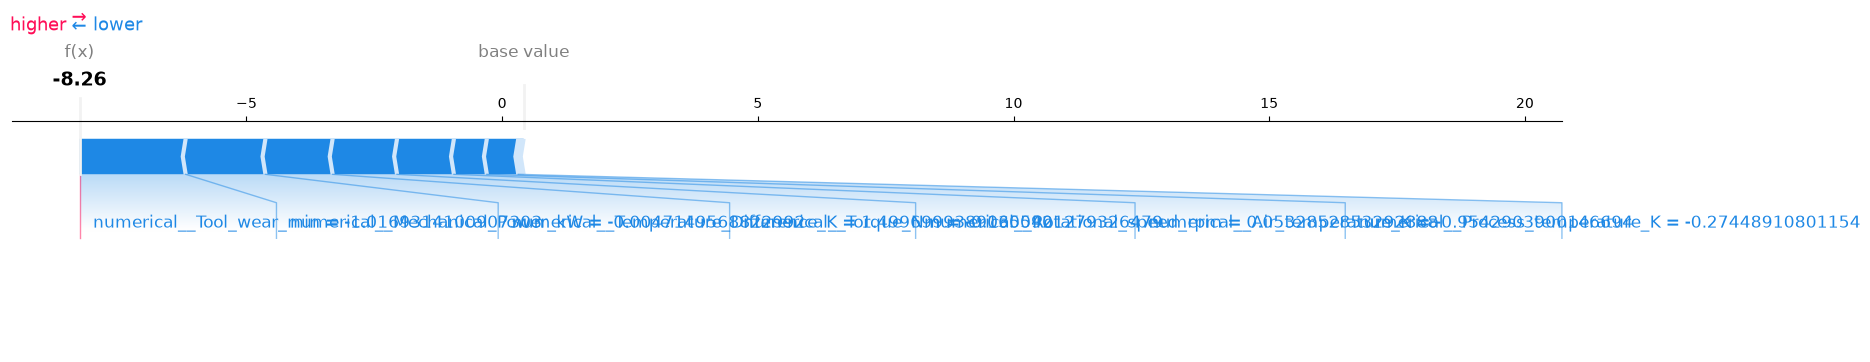

In [40]:
# Explain the selected machine
sample_shap_values = explainer.shap_values(sample)

shap.force_plot(
    explainer.expected_value,
    sample_shap_values[0],
    sample.iloc[0],
    matplotlib=True
)

plt.show()

In [41]:
import numpy as np

sample_probability = best_xgb_model.predict_proba(sample)[0][1]

sample_prediction = int(sample_probability >= 0.40)

print("Failure Probability:", round(sample_probability * 100, 4), "%")

print("Predicted Status:",
      "Failure Risk" if sample_prediction == 1 else "Normal")

print("Decision Threshold:", best_threshold)

Failure Probability: 0.0257 %
Predicted Status: Normal
Decision Threshold: 0.4


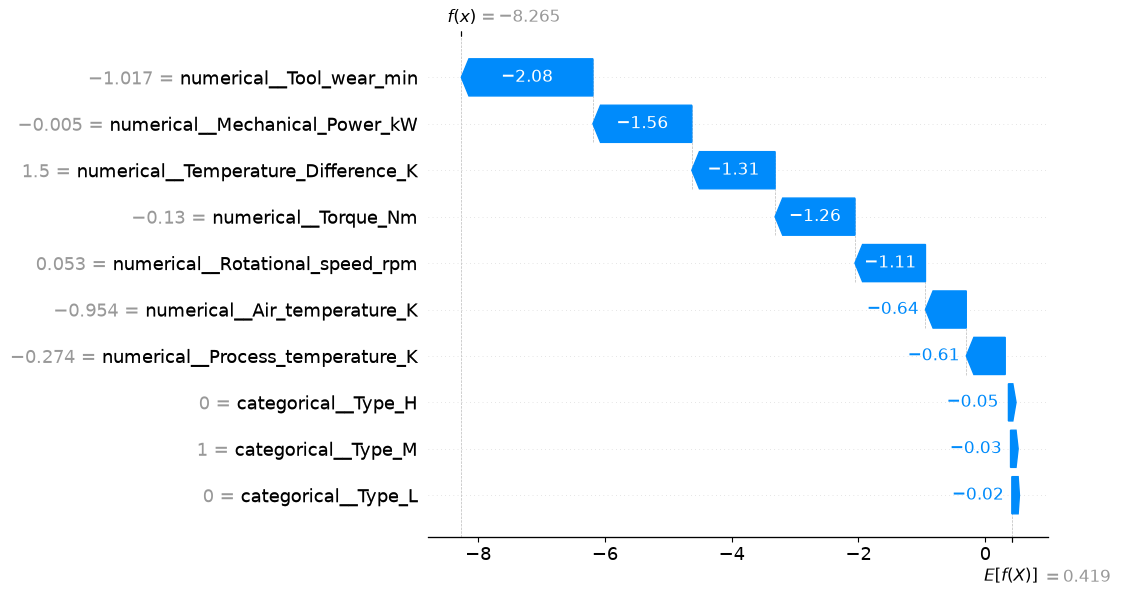

In [42]:
# Generate SHAP explanation for this machine
sample_explanation = explainer(sample)

# Display readable waterfall plot
shap.plots.waterfall(
    sample_explanation[0],
    max_display=10
)

In [43]:
sample_probability = best_xgb_model.predict_proba(sample)[0][1]

sample_prediction = int(sample_probability >= best_threshold)

print("Individual Machine Prediction")
print("------------------------------")

print(f"Failure Probability: {sample_probability * 100:.4f}%")
print(f"No Failure Probability: {(1-sample_probability) * 100:.4f}%")

print("Prediction:",
      "Failure Risk" if sample_prediction == 1 else "Normal")

print("Threshold:", best_threshold)

Individual Machine Prediction
------------------------------
Failure Probability: 0.0257%
No Failure Probability: 99.9743%
Prediction: Normal
Threshold: 0.4


In [44]:
from xgboost import XGBClassifier

# Calculate class weight using all training records
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

final_scale_weight = negative_count / positive_count

# Get optimized parameters
best_params = random_search.best_params_.copy()

# Create final model
final_xgb_model = XGBClassifier(
    **best_params,
    scale_pos_weight=final_scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train using all 8,000 training records
final_xgb_model.fit(X_train_xgb, y_train)

print("Final XGBoost model trained successfully!")

Final XGBoost model trained successfully!


FINAL XGBOOST TEST RESULTS
---------------------------
Accuracy: 0.985
Precision: 0.7567567567567568
Recall: 0.8235294117647058
F1 Score: 0.7887323943661971
ROC-AUC: 0.9785653391791499
PR-AUC: 0.8832047327680923

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.76      0.82      0.79        68

    accuracy                           0.98      2000
   macro avg       0.88      0.91      0.89      2000
weighted avg       0.99      0.98      0.99      2000



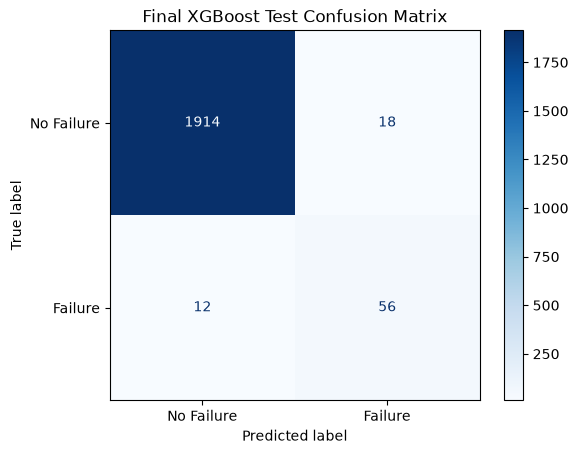

In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Test probabilities
y_test_prob = final_xgb_model.predict_proba(X_test_xgb)[:, 1]

# Apply selected threshold
final_threshold = 0.40

y_test_pred = (
    y_test_prob >= final_threshold
).astype(int)

# Calculate metrics
print("FINAL XGBOOST TEST RESULTS")
print("---------------------------")

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_test_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_test_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))
print("PR-AUC:", average_precision_score(y_test, y_test_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Final XGBoost Test Confusion Matrix")
plt.show()

In [46]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_xgb_model,
    "../models/final_xgboost_model.pkl"
)

joblib.dump(
    0.40,
    "../models/decision_threshold.pkl"
)

print("Final model and threshold saved successfully!")

Final model and threshold saved successfully!


In [47]:
joblib.dump(
    explainer,
    "../models/shap_explainer.pkl"
)

['../models/shap_explainer.pkl']